# Aula 02 - Classificação, Regressão Logística, Redes Neurais e IA

In [49]:
# Imports e Configuração Inicial
import random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#mport torch
#import torch.nn as nn

#from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# Seeds de reprodutibilidade: garantem que os resultados sejam consistentes execuções para uma mesma seed
SEED = 314
random.seed(SEED)
np.random.seed(SEED)
#torch.manual_seed(SEED)

# Classificação

Bom até agora aprendemos como uma regressão linear funciona, e como ela aprende, mas vamos espandir mais um pouco o escopo dos dados em que trabalhamos, dentro do mundo real há muitos momentos onde precisamos prever variaveis qualitativas, por exemplo, supondo que trabalhamos em um banco, e recebemos um conjunto de dados de informações das transações de vários clientes, nosso Y diz se a transação foi fraudulenta ou não, e esse valor vai ser dado por 0 se a transação foi normal e 1 se foi fraude.

A principal diferença desse caso para o que vimos até agora é justamente o que queremos prever, os valores a serem previstos são uma classe, ela classifica a transação como fraude ou não fraude, já anteriormente queriamos descobrir valores quantitativos e reais de -$\infty$ a +$\infty$.

Para esse caso de uso utilizamos os modelos de Classificação, existem inumeros modelos de classificação, tanto que fazem classificação binaria, onde a saída é duas classes diferentes, como se um e-mail é span ou não, se o paciente tem uma doença ou não, ou até para valores multclasse, como, por exemplo, dado caracteríscas de altura, peso, motor, e tamanho de um carro, qual categoria ele pertence.

# Regressão Logistica

Vamos pensar em um cenário específico onde temos dados da quantidade de transações que clientes de um banco fazem na semana, e o Y é se eles são fraudadores ou não;

Text(0.5, 0, 'Quantidade de transações')

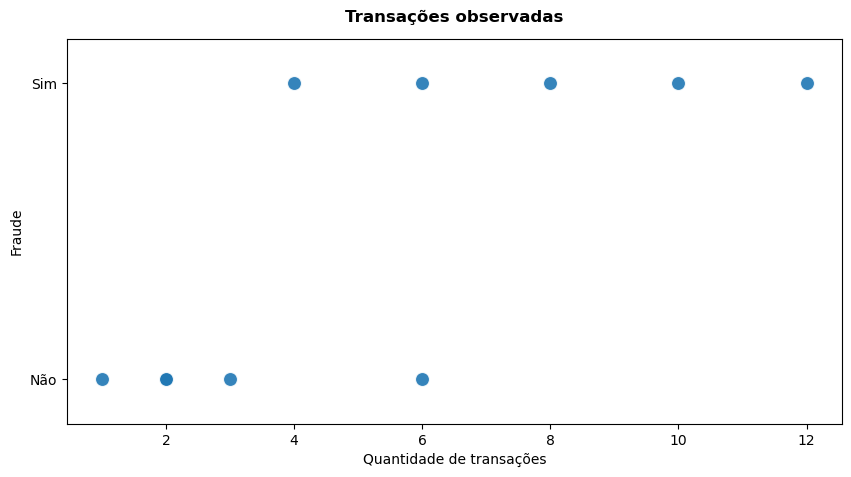

In [50]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=110,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    ax=ax
)
ax.set_title('Transações observadas', pad=12, weight='bold')
ax.set_ylabel('Fraude')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel('Quantidade de transações')

É claro que os dados não tem uma correlação linear, mas como sabemos apenas a regressão linear até agora, vamos utiliza-la para tentar aprender com esses dados;

In [51]:
x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.11]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.07353
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11.06]


In [52]:
y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

Erro: 0.11
Aprendizado: 0.55%


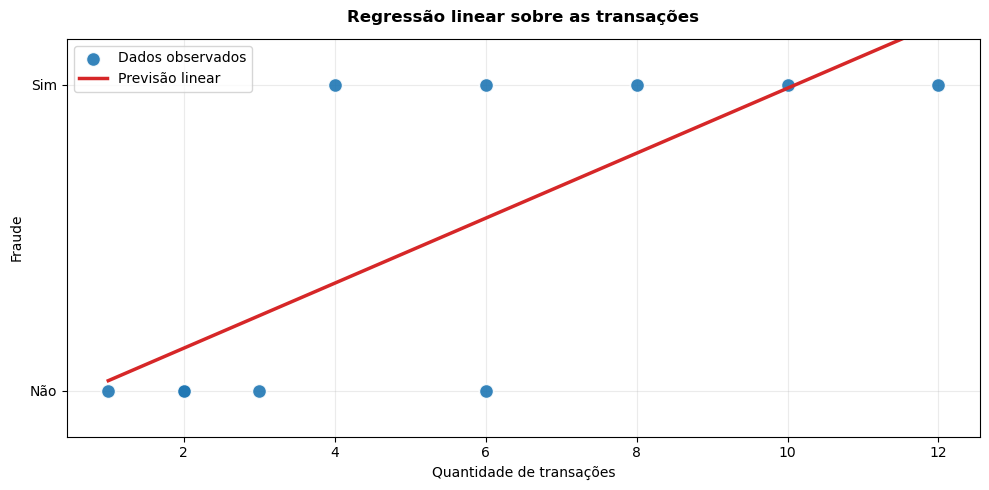

In [53]:
ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear sobre as transações', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()

Podemos tirar algumas conclusões desses dados, primeiro que como já haviamos imaginado o modelo de regressão linear não é o mais apropriado para esse tipo de dado, mas por que?

Bom isso tem alguns motivos o primeiro já falamos, mesmo que o modelo seja treinado apenas com valores qualitativos de Y, ele não foi preparado para retornar apenas esse tipo de valores, então como visto no modelo, ele previu alguns valores maiores que 1, o que é impossível já que nosso Y só tem valores 0 ou 1, outro motivo é que nosso modelo fica muito sensível a outliers, vamos supor que esse mesmo modelo tenha um outlier, vamos ver como ele ficaria;

Erro: 0.19
Aprendizado: 0.23%


Text(0.5, 0, 'Quantidade de transações')

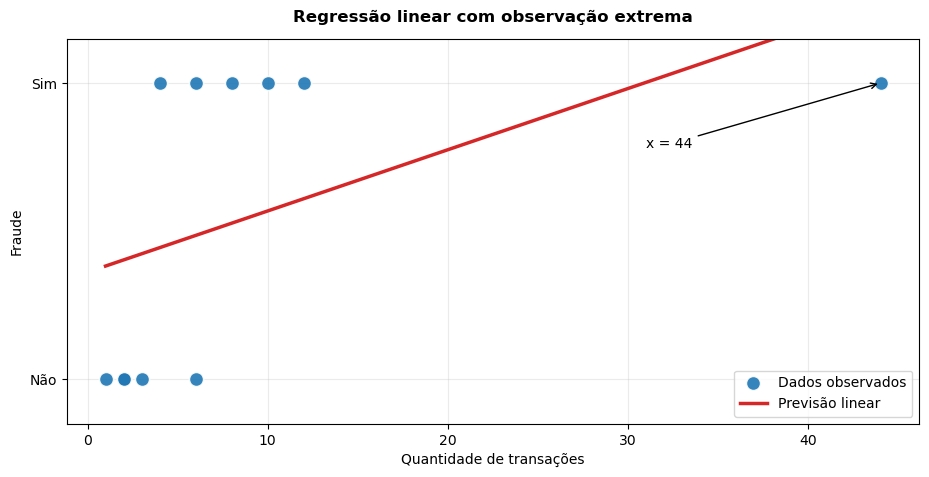

In [54]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LinearRegression();
model.fit(x, fraude)

y_pred = model.predict(x)
mse = mean_squared_error(fraude, y_pred)
r2 = r2_score(fraude, y_pred)
print(f'Erro: {mse:.2f}')
print(f'Aprendizado: {r2:.2f}%')

ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))

sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    y_pred[ordem],
    color='#d62728',
    linewidth=2.5,
    label='Previsão linear'
)
ax.set_title('Regressão linear com observação extrema', pad=12, weight='bold')
ax.set_yticks([0, 1], labels=['Não', 'Sim'])
ax.set_ylim(-0.15, 1.15)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True)
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
ax.set_ylabel('Fraude')
ax.set_xlabel('Quantidade de transações')

Ok, já entendemos que não podemos usar somente a regressão linear nesse caso, mas qual curva descreve melhor esses dados?

A regressão logística estima a **probabilidade** de uma observação pertencer à classe 1. Para isso, ela usa uma curva sigmoide, em formato de S, cujos valores sempre ficam entre 0 e 1.

Para visualizar essa curva, não podemos usar `model.predict()`: esse método já transforma a probabilidade em uma classe final, 0 ou 1, usando por padrão o limiar de 0,5. Por isso, ele gera apenas pontos ou degraus. Usamos `model.predict_proba()` para obter a probabilidade de fraude e calculamos essa probabilidade para uma sequência ordenada de quantidades de transações.

O valor 44 é um possível outlier e amplia muito o eixo x. Assim, a parte curva da sigmoide, que ocorre aproximadamente entre 0 e 12 transações, parece comprimida no gráfico completo. Os dois gráficos abaixo mostram a mesma curva: o primeiro preserva a escala completa e o segundo amplia a região em que a transição acontece.

Acurácia no treino: 80.00%


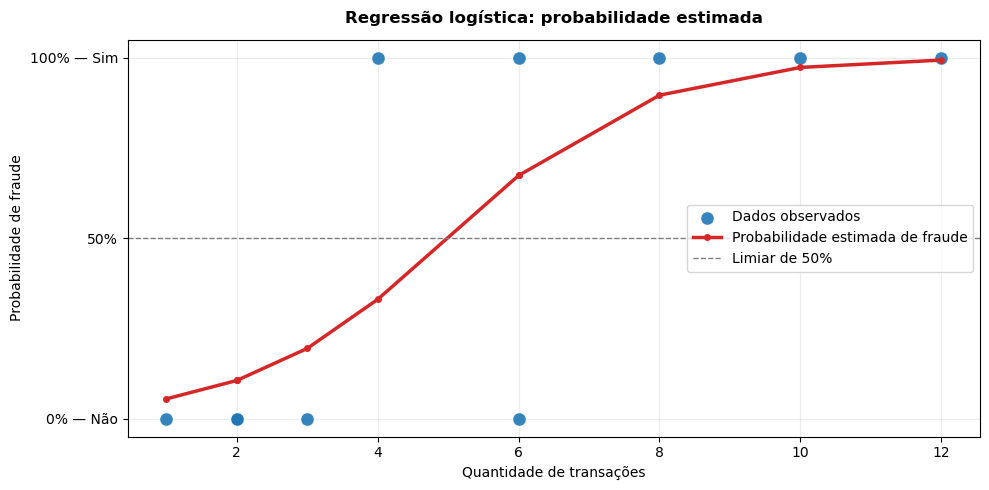

In [55]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística: probabilidade estimada', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
plt.tight_layout()

Acurácia no treino: 81.82%


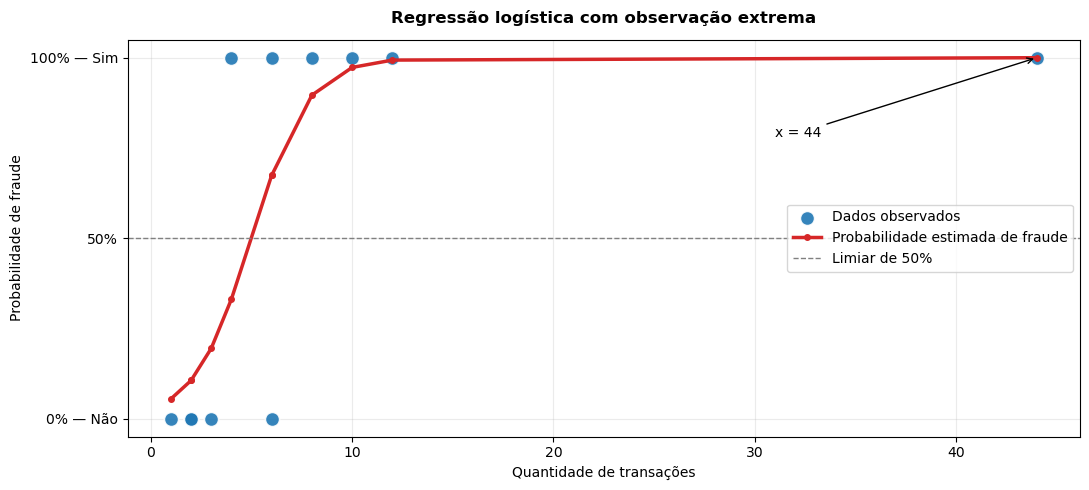

In [56]:
quant_transactions = np.array([2, 6, 1, 12, 2, 10, 3, 6, 4, 8, 44]);
fraude = np.array([0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1]);

x = quant_transactions.reshape(-1, 1)
model = LogisticRegression();
model.fit(x, fraude)

print(f'Acurácia no treino: {model.score(x, fraude) * 100:.2f}%')

prob_fraude = model.predict_proba(x)


ordem = np.argsort(quant_transactions)
fig, ax = plt.subplots(figsize=(11, 5))
sns.scatterplot(
    x=quant_transactions,
    y=fraude,
    s=105,
    color='#1f77b4',
    edgecolor='white',
    linewidth=1.2,
    alpha=0.9,
    label='Dados observados',
    ax=ax
)
ax.plot(
    quant_transactions[ordem],
    prob_fraude[ordem, 1],
    color='#d62728',
    linewidth=2.5,
    marker='o',
    markersize=4,
    label='Probabilidade estimada de fraude'
)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Limiar de 50%')
ax.set_title('Regressão logística com observação extrema', pad=12, weight='bold')
ax.set_xlabel('Quantidade de transações')
ax.set_ylabel('Probabilidade de fraude')
ax.set_yticks([0, 0.5, 1], labels=['0% — Não', '50%', '100% — Sim'])
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=True, loc='center right')
ax.annotate('x = 44', xy=(44, 1), xytext=(31, 0.78), arrowprops={'arrowstyle': '->'})
plt.tight_layout()

É notável que ela além de ter um desempenho muito melhor com os dados, a regressão logistica é muito menos sensível a outliers, mas como ela funciona?

A regressão logística é uma regressão com uma função de ativação sigmoid que nos retorna um valor entre 0 e 1 que é a probabilidade do $\hat Y$ ser 1;

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} ou \frac{e^z}{1 + e^z}$$
É notável que, além de apresentar um bom desempenho nesses dados, a regressão logística seja menos sensível a valores extremos. 
A regressão logística calcula uma combinação linear das entradas, $z = WX + b$, e aplica a função sigmoide. O resultado é um valor entre 0 e 1, interpretado como a probabilidade de $\hat{Y}$ pertencer à classe 1:

$$
P(Y = 1 \mid X) = \sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}
$$

onde $z = WX + b$, $\sigma$ representa a função sigmoide e $e$ é a constante de Euler, aproximadamente igual a 2,718.
$$p = \sigma(WX+b)$$

onde $z$ é nossa função linear $WX + b$ e $e$ é a constante de Euler aproximadamente 2,718;



Vamos fazer um exemplo prático onde $W = 0.5$ $b = -3$ $ X = 2$
Substituindo os valores, primeiro calculamos:

$$z = wX + b = 0.5 \cdot 2 - 3 = -2$$

Então, a probabilidade de $Y = 1$ é:

$$P(Y = 1 \mid x) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + e^2} $$

In [57]:
#Prática da função

a = 0.5
x = 2
b = -3

def FuncaoLogistica(a, x, b):
    e = 2.718
    z = a *x +b
    resultado = 1 / (1 + e ** (-z))
    return resultado

logistic = FuncaoLogistica(a, x, b)
print(f'{logistic:.2}')


0.12


Agora entendemos como nosso modelo calcula as probabilidades, mas como nosso modelo aprende?

Dentro da Regressão linear nossa função de custo era a Mean Squared Error, mas ela não vai funcionar muito bem com nossa regressão logistica, para esse modelo vamos usar a Binary Cross Entropy

# Função de Custo Binary Cross Entropy

Vamos entender melhor essa função de custom por que binaria? o que é entropia cruzada?

**Teoria da informação** <br>

O termo entropia vem da teoria da informação, mais especificamente do paper "A Mathematical Theory of Comunnication" que foi publicada por Claude Shannon em 1948 (Inspiração do Dario Amoday para o nome do Claude Code), dentro desse artigo a preocupação dele era sobre como transmitir mensagens ou informações por meio de um canal, ele queria entender qual seria a melhor forma e a forma mais eficiente possível dessa transmissão acontecer.

Dentro desse paper surgiu o conceito de entropia cruzada, mas antes de entendermos o que é a cross entropy, precisamos voltar um pouco, vamos entender o que era informação para o Claude.

**Informação**

A informação vai quantificar a incerteza de um evento, ou seja, quanto maior informação que precisamos menor é a probabilidade de um evento acontecer, e eventos de alta probabilidade são menos surpreendentes, então precisam de menos informação para acontecer;
fórmula da informação <br>
$I(x) = -LogP(x)$
Exemplo:

Supondo que queremos descobrir a quantidade de informação que precisamos para que um time seja campeão mundial as probabilidades são
Corinthians(60%) <br>
Real Madrid(20%) <br>
Al Hilal(20%) <br>
Palmeiras(0%) <br>

A informação que precisamos para o Corinthians ser campeão, é $-ln(0,60)$ que é aproximadamente $0,51$; <br>
A informação que precisamos para o Real Madrid ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>
A informação que precisamos para o Al Hilal ser campeão, é $-ln(0,20)$ que é aproximadamente $1,60$; <br>

Com esses dados é possível vizualizar e consolidar o que foi teorizado por Sannon, que quanto menor a probabilidade maior a quantidade de informação que precisamos para que esse evento aconteça;

**Entropia**

A entropia quantifica a quantidade de informação relativa de uma variável dado uma distribuição de probabilidades, ou seja, diferente da informação que quantifica infromações apenas para um evento, a entropia calcula a quantidade de informação para uma varivel;

Vamos ver um exemplo dessa diferença, dentro do exemplo acima descrimos a quantidade de informação que precisamos para o evento Corinthians compeão mundial, Real madrid campeão mundial ou Al hilal campeão mundial, já a entropia calcularia a quantidade de informação da variavel "quem será campeão mundial?" dado o conjunto de probabilidades de cada clube;

$$
H(X) = -\sum_{i=1}^{n} p(x_i)\log p(x_i)
$$

onde $p(x_i)$ é a probabilidade de cada resultado possível, ou seja, somamos o produto da probabilidade de cada evento pela quantidade de informação que ele precisa.

Ficaria então = $$- (0,6\log(0,6)) + (0,2\log(0,2)) + (0,2\log(0,2)) \approx 0,95 $$ de informação em média


In [58]:
#construir uma função que calcula a informação
def Informacao(p):
    return -np.log(p)
print(f'{Informacao(0.2):.2f}')

1.61


In [59]:
#construir uma função que calcula entropia
def Entropia(p):
    entropia = 0
    for i in p:
        entropia -= i * np.log(i)
    return entropia
p = [0.6, 0.2, 0.2]

print(Entropia(p))

0.9502705392332347



**Entropia Cruzada**

Agora falar de Cross entropy é muito mais fácil, já que a entropia cruzada é a entropia relativa de duas distribuições de probabilidade, para exemplificar, vamos supor que nosso evento de times sejá a probabilidade que uma casa de aposta publicou com base em um estudo que ela fez, já outra casa de aposta fez outro estudo onde as probabilidades eram:

        Casa A                    |                  Casa B        
    Corinthians (60%)             |              Corinthians (90%) 
    Real madrid (20%)             |              Real madrid (8%)  
    Al Hilal (20%)                |              Al Hilal (2%)     

Para calcular a entropia cruzada dessas duas distribuições de probabilidade vamo utilizar a formula:

A entropia cruzada entre uma distribuição de referência $P$ e uma distribuição estimada $Q$ é:

$$
H(P,Q) = -\sum_{i=1}^{n} p(x_i)\log q(x_i)
$$

Considerando a Casa A como distribuição de referência e a Casa B como estimativa:

$$
H(P,Q) = -\bigl[
0{,}6\ln(0{,}9) +
0{,}2\ln(0{,}08) +
0{,}2\ln(0{,}02)
\bigr]
\approx 1{,}35
$$

E se calculassemos a entropia deles individualmente, teríamos:

$$
H(P) = -\sum_{i} p_i \ln(p_i)
= -\bigl[0{,}6\ln(0{,}6) + 0{,}2\ln(0{,}2) + 0{,}2\ln(0{,}2)\bigr]
\approx 0{,}95
$$

e

$$
H(Q) = -\sum_{i} q_i \ln(q_i)
= -\bigl[0{,}9\ln(0{,}9) + 0{,}08\ln(0{,}08) + 0{,}02\ln(0{,}02)\bigr]
\approx 0{,}38
$$

Ou seja, a distribuição da Casa A tem uma entropia maior, porque como as probabilidades dos times são mais próxima isso torna o evento mais incerto, o que significa que precisariamos que mais informação para saber se ele aconteceria. Isso também explica por que a entropia cruzada $H(P,Q)$ é maior que a entropia de $P$ e de $Q$ individualmente: ela mede o custo de aproximar duas distribuições diferentes.


**Binary Cross Entropy**

A entropia binária cruzada (*binary cross-entropy*, ou BCE) adapta essa ideia a problemas de classificação binária. Para $N$ amostras, ela é definida como:

$$
\mathrm{BCE}
= -\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\ln(\hat{y}_i) +
(1-y_i)\ln(1-\hat{y}_i)
\right]
$$

- $N$: número de amostras.
- $y_i$: rótulo real da amostra $i$, igual a $0$ ou $1$.
- $\hat{y}_i$: probabilidade prevista pelo modelo de que a amostra pertença à classe $1$, entre $0$ e $1$ — calculada com a função sigmoide.

Essa função de custo é muito interessante pois ela é quase duas funções em uma, pois quando o valor for negativo vamos usar o lado direito da função, e quando for positivo vamos usar o lado esquerdo, mas vamos entender como isso funciona:

supondo que utilizamos o resultado da função sigmoid que calculamos lá em cima;

Caso $y_i$ = 1:
$$- 1\ln(0.1192) + (1-1) \ln(1-0,1192)$$
$$- 1\ln(0.1192)$$
$$-(-2,12)$$
Resultado = $\approx2,12$


Note que nesse caso o lado direito vai sair da fórmula pois vamos multiplica-lo por 0 após subtrairmos $1 - (\hat{y_i})$ já que nosso $(\hat{y_i})$ é 1;

Caso $y_i$ = 0:

$$- 0\ln(0.1192) + (1-0) \ln(1-0,1192)$$
$$- 1\ln(0,88)$$
$$-(-0,12)$$

Resultado = $\approx0,12$

Nesse caso cortamos a parte esqueda da equação, já que nosso $y_i$ = 0, também é possível notar que nossa função de custo retornou um valor bem maior quando o valor original era 1, já que nosso modelo errou bem mais de que quando era 0, dado que o $\hat{y}$ era 11,92% de chance do valor ser 1.

Para minimizar essa função vamos utilizar o conceito de gradiente descente aprendidos na última aula.

**Decision Boundary**

Também precisamos definir a fronteira de decisão. Por padrão, usamos o limiar de 50%: se a probabilidade estimada de a observação pertencer à classe 1 for maior ou igual a 50%, classificamos o resultado como 1; caso contrário, classificamos como 0.

Como a função sigmoide é crescente e $\sigma(0)=0{,}5$, esse critério também pode ser escrito em função de $z$:

$$
\hat{y} \geq 0{,}5 \iff z \geq 0
$$

$$
\hat{y} < 0{,}5 \iff z < 0
$$ 

Há também casos onde precisaremos mudar a decision boundary, pois queremos um modelo com uma precisão muito grando, para casos onde estamos lidando com classificação de remédios por exemplo.


# Aplicando Regressão Logistica em um dataset Real

In [60]:
df = pd.read_csv('datasets/Diagnosis.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [62]:
df = df.drop(columns=['id', 'Unnamed: 32'])
df = df.dropna()
df['diagnosis'] = df['diagnosis'].replace({'M': 0, 'B': 1}).astype(float)
df.head()

/tmp/ipykernel_36638/1114436661.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['diagnosis'] = df['diagnosis'].replace({'M': 0, 'B': 1}).astype(float)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0.0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,0.0,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,0.0,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,0.0,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,0.0,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<Axes: xlabel='radius_mean', ylabel='diagnosis'>

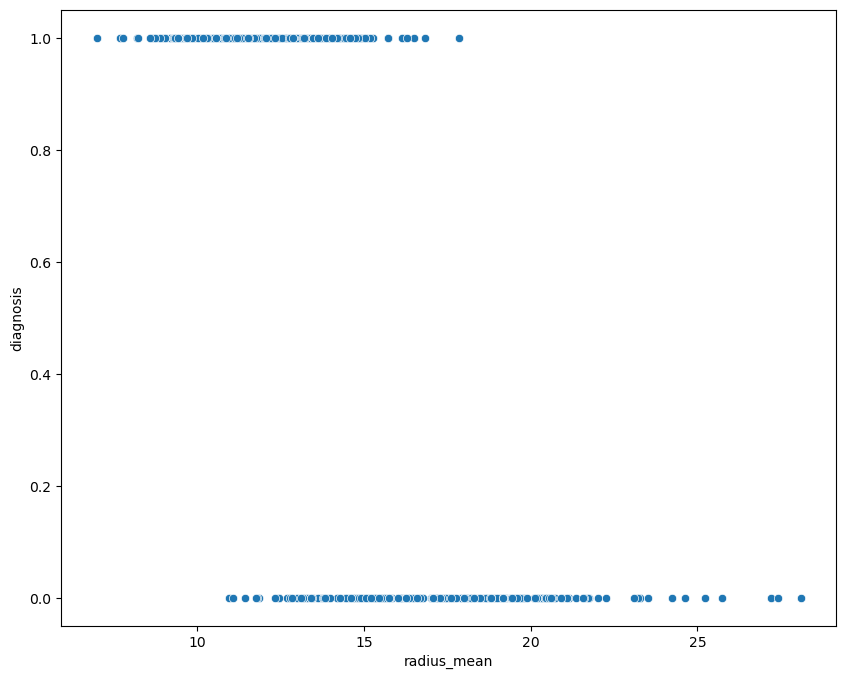

In [63]:
#scatter plot Radius_mean e Diagnosis
fig, ax = plt.subplots(figsize=(10,8))
sns.scatterplot(x=df['radius_mean'], y=df['diagnosis'])

In [64]:
#Construndo o modelo com sklearn
x = df.drop(columns='diagnosis')
y = df['diagnosis']
modelo = LogisticRegression()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

LogisticRegressor = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
LogisticRegressor.fit(x_train, y_train)
print(f'Acurácia no treino: {LogisticRegressor.score(x_train, y_train) * 100:.2f}%')
print(f'Acurácia no teste: {LogisticRegressor.score(x_test, y_test) * 100:.2f}%')

Acurácia no treino: 98.68%
Acurácia no teste: 97.37%


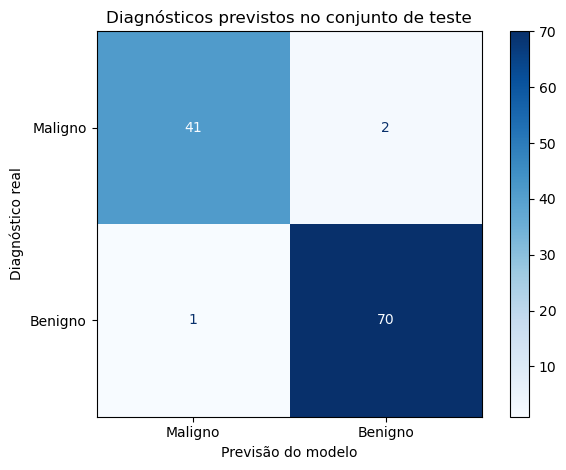

In [65]:
y_pred = LogisticRegressor.predict(x_test)

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])

grafico = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Maligno', 'Benigno']
)
grafico.plot(cmap='Blues', values_format='d')

plt.title('Diagnósticos previstos no conjunto de teste')
plt.xlabel('Previsão do modelo')
plt.ylabel('Diagnóstico real')
plt.tight_layout()
plt.show()